In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

In [3]:
import pandas as pd

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Analyzing Best-Seller Trends Across Product Categories

In [4]:
# Tabla cruzada entre categoría y Best Seller
tabla = pd.crosstab(df["category"], df["isBestSeller"])

tabla.head(10)

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
Agricultural Equipment & Supplies,8421,109
Alexa Built-In Devices,106,1
Art & Craft Supplies,253,5
Arts & Crafts,9319,230


In [5]:
# Calcular el porcentaje de best-sellers por categoría
tabla["porcentaje_best_seller"] = (
    tabla[True] / tabla.sum(axis=1) * 100
)

# Ordenar de mayor a menor porcentaje
tabla.sort_values("porcentaje_best_seller", ascending=False).head(10)

isBestSeller,False,True,porcentaje_best_seller
category,,,
Grocery,9008,556,5.813467
Smart Home Security & Lighting,98,6,5.769231
Health & Personal Care,9017,552,5.768628
Mobile Phone Accessories,248,11,4.247104
Power & Hand Tools,8353,306,3.533895
"Billiard, Snooker & Pool",241,8,3.212851
Pet Supplies,9152,285,3.020028
Home Brewing & Wine Making,239,7,2.845528
Mirrors,243,7,2.800000


Grocery ocupa el primer puesto, con aproximadamente 6 productos superventas por cada 100.
También es interesante que Smart Home Security & Lighting tenga un porcentaje elevado, aunque solo cuenta con 104 productos. Por eso conviene tener en cuenta el tamaño de cada categoría al interpretar los resultados.

### Conclusión — Análisis de Best-Sellers

Tras calcular la proporción de productos superventas por categoría, observamos que **Grocery (5,81 %)**, **Smart Home Security & Lighting (5,77 %)** y **Health & Personal Care (5,77 %)** presentan los porcentajes más elevados.

Esto indica que la presencia de productos best-seller varía entre categorías. Sin embargo, algunas tienen muchos menos productos que otras, por lo que debemos interpretar los porcentajes teniendo en cuenta el tamaño de cada grupo.

Para comprobar si existe una relación estadísticamente significativa entre la categoría del producto y su condición de best-seller, realizaremos una prueba de chi-cuadrado.

H₀: La categoría del producto y su condición de best-seller son independientes.
H₁: Existe una asociación entre ambas variables.

In [6]:
from scipy.stats import chi2_contingency

# Crear la tabla de frecuencias original
tabla_chi = pd.crosstab(df["category"], df["isBestSeller"])

# Realizar el test chi-cuadrado
chi2, p_value, dof, expected = chi2_contingency(tabla_chi)

print("Chi-cuadrado:", chi2)
print("P-value:", p_value)
print("Grados de libertad:", dof)

Chi-cuadrado: 36540.20270061387
P-value: 0.0
Grados de libertad: 295


### Conclusión — Prueba de chi-cuadrado

Hemos realizado una prueba de chi-cuadrado para analizar si existe una relación entre la categoría de los productos y su condición de best-seller.

El resultado obtenido es un estadístico χ² de **36.540,20**, con un p-value extremadamente pequeño (inferior a 0,05).

Por tanto, **rechazamos la hipótesis nula** y concluimos que existe una asociación estadísticamente significativa entre ambas variables.

Esto significa que la proporción de productos superventas no es igual en todas las categorías. Sin embargo, todavía necesitamos calcular Cramérs para determinar la intensidad de esta asociación.

El chi-cuadrado nos dice si existe una asociación, pero Cramér's V nos ayuda a medir su intensidad.
Su valor va de 0 a 1:
- Cercano a 0: asociación débil.
- Cercano a 1: asociación fuerte.

In [7]:
# Calcular Cramér's V
n = tabla_chi.to_numpy().sum()
filas, columnas = tabla_chi.shape

cramers_v = np.sqrt(
    chi2 / (n * min(filas - 1, columnas - 1))
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


0,1223 indica una asociación débil entre la categoría del producto y su condición de best-seller.
Esto es interesante porque el chi-cuadrado nos había indicado que la relación era estadísticamente significativa.

### Conclusión — Cramér's V

El valor obtenido de **Cramér's V es 0,1223**, lo que indica una asociación débil entre la categoría del producto y su condición de best-seller.

Aunque la prueba de chi-cuadrado ha demostrado que existe una relación estadísticamente significativa entre ambas variables, su intensidad es baja.

Desde una perspectiva empresarial, esto sugiere que la categoría puede influir en la probabilidad de que un producto sea superventas, pero por sí sola no es suficiente para explicar su éxito.

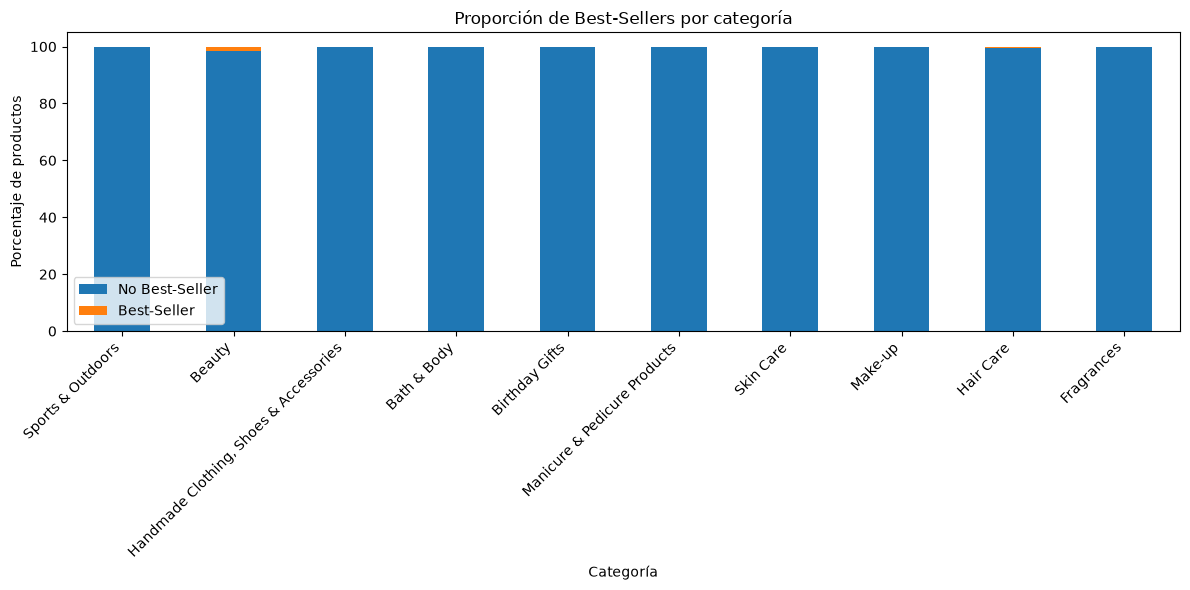

In [8]:
# Seleccionar las 10 categorías con más productos
top_10 = df["category"].value_counts().head(10).index

# Calcular proporciones de best-sellers
tabla_grafico = pd.crosstab(
    df["category"],
    df["isBestSeller"],
    normalize="index"
) * 100

# Crear gráfico de barras apiladas
tabla_grafico.loc[top_10].plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Proporción de Best-Sellers por categoría")
plt.xlabel("Categoría")
plt.ylabel("Porcentaje de productos")
plt.xticks(rotation=45, ha="right")
plt.legend(["No Best-Seller", "Best-Seller"])
plt.tight_layout()
plt.show()

### Conclusión — Gráfico de barras apiladas

El gráfico muestra que la mayoría de los productos de las diez categorías más numerosas de Amazon UK no son best-sellers.

La proporción de productos superventas es reducida en todas las categorías representadas, aunque existen pequeñas diferencias entre ellas.

Esto coincide con los resultados anteriores: existe una asociación estadísticamente significativa entre la categoría y la condición de best-seller, pero su intensidad es débil según Cramér's V (0,1223).

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

In [9]:
# Calcular los cuartiles del precio
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

# Calcular el rango intercuartílico
IQR = Q3 - Q1

# Calcular los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

Q1: 9.99
Q3: 45.99
IQR: 36.0
Límite inferior: -44.01
Límite superior: 99.99000000000001


Según el método IQR, consideramos valores atípicos los precios superiores a 99,99 £ o inferiores a -44,01 £.
Como los precios no pueden ser negativos, en la práctica nos interesan especialmente los productos que superan las 99,99 £.

In [10]:
# Crear un DataFrame sin outliers de precio
df_clean = df[
    (df["price"] >= limite_inferior) &
    (df["price"] <= limite_superior)
].copy()

# Comprobar cuántos productos hemos eliminado
print("Productos originales:", len(df))
print("Productos sin outliers:", len(df_clean))
print("Outliers eliminados:", len(df) - len(df_clean))

Productos originales: 2443651
Productos sin outliers: 2115963
Outliers eliminados: 327688


Hemos eliminado aproximadamente el 13,41 % de los productos, conservando el 86,59 % para el análisis.
Esto significa que trabajaremos con df_clean para estudiar los precios sin que los valores extremadamente altos distorsionen tanto las comparaciones.

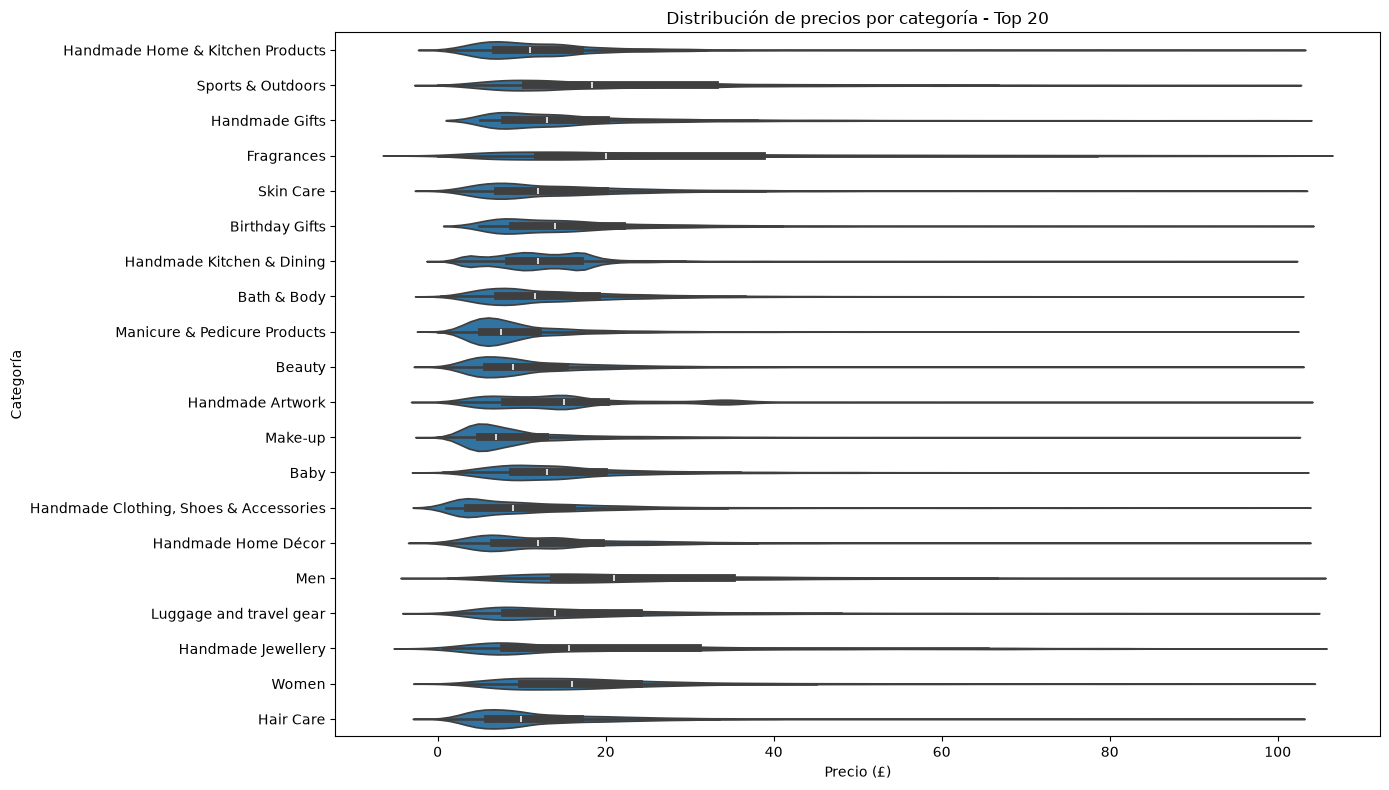

In [11]:
# Seleccionar las 20 categorías con más productos
top_20 = df_clean["category"].value_counts().head(20).index

# Crear el violin plot
plt.figure(figsize=(14, 8))

sns.violinplot(
    data=df_clean[df_clean["category"].isin(top_20)],
    x="price",
    y="category"
)

plt.title("Distribución de precios por categoría - Top 20")
plt.xlabel("Precio (£)")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

### Conclusión — Violin Plot

El gráfico muestra que la mayoría de los productos de las 20 categorías más numerosas de Amazon UK se concentran en rangos de precios bajos.

Sin embargo, existen diferencias entre categorías. Algunas, como Fragrances, Men y Women, presentan una mayor dispersión de precios, mientras que otras, como Make-up, concentran sus productos en precios más reducidos.

Esto indica que la distribución de precios varía según la categoría del producto.

In [12]:
# Calcular la mediana de precio por categoría
medianas = df_clean.groupby("category")["price"].median()

# Ordenar de mayor a menor
medianas.sort_values(ascending=False).head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

La categoría Desktop PCs (ordenadores de sobremesa) tiene la mediana más alta, con 74 £.
Esto significa que el 50 % de los productos de esta categoría tiene un precio igual o inferior a 74 £ y el otro 50 % tiene un precio igual o superior.

### Conclusión — Mediana de precios por categoría

Tras analizar todas las categorías del dataset sin valores atípicos, observamos que **Desktop PCs presenta la mediana de precio más alta, con 74 £**, seguida de Boxing Shoes (69,79 £) y Tablets (69 £).

Esto indica que los productos de estas categorías tienden a tener precios centrales más elevados que los de otras categorías analizadas.

La mediana permite comparar los precios habituales de cada categoría sin que los valores extremos tengan tanta influencia como en la media.

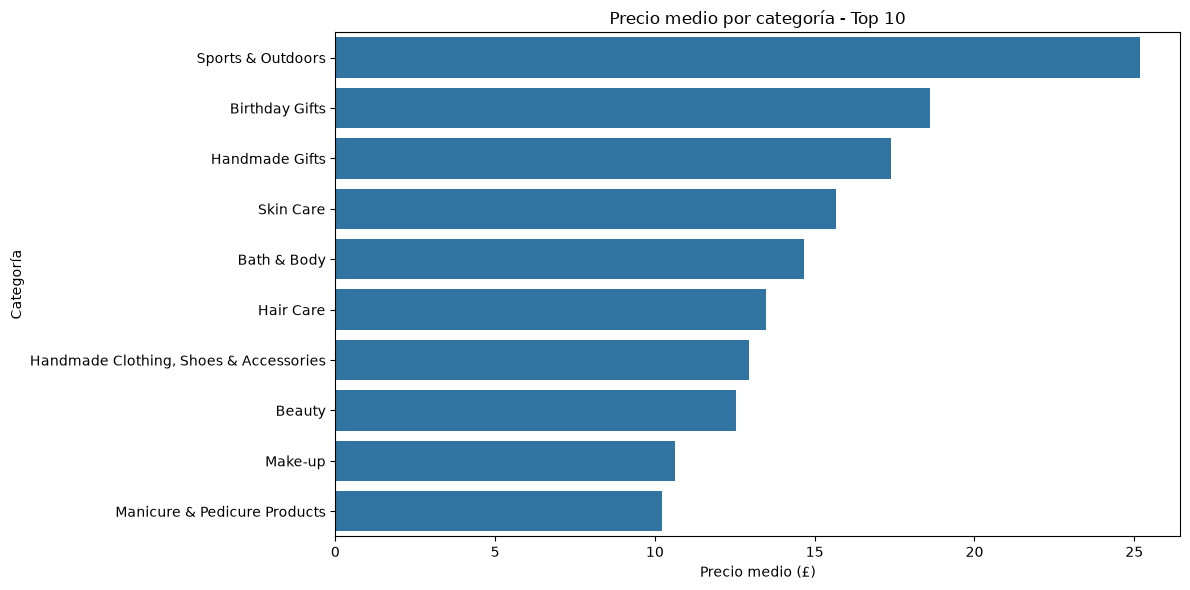

In [13]:
# Seleccionar las 10 categorías con más productos
top_10 = df_clean["category"].value_counts().head(10).index

# Calcular el precio medio de esas categorías
precios_medios = (
    df_clean[df_clean["category"].isin(top_10)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

# Crear gráfico de barras
plt.figure(figsize=(12, 6))
sns.barplot(x=precios_medios.values, y=precios_medios.index)

plt.title("Precio medio por categoría - Top 10")
plt.xlabel("Precio medio (£)")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

### Conclusión — Precio medio por categoría

El gráfico muestra que, entre las diez categorías con mayor número de productos, **Sports & Outdoors presenta el precio medio más elevado, aproximadamente 25 £**, seguida de Birthday Gifts y Handmade Gifts.

Por el contrario, Manicure & Pedicure Products y Make-up presentan los precios medios más bajos.

Estos resultados sugieren que la categoría del producto está relacionada con su nivel de precios, aunque el análisis se limita a las diez categorías más numerosas y al dataset sin valores atípicos.

In [14]:
# Calcular el precio medio de todas las categorías
precios_medios_todas = (
    df_clean.groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

precios_medios_todas.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

### Conclusión — Precio medio por categoría

Tras analizar todas las categorías del dataset sin valores atípicos, observamos que **Motherboards presenta el precio medio más alto, con 68,77 £**, seguida de Boxing Shoes (67,42 £) y Desktop PCs (66,92 £).

Es interesante destacar que Desktop PCs tenía la mediana más elevada, mientras que Motherboards lidera el ranking de precios medios.

Esto demuestra que la media y la mediana pueden ofrecer resultados diferentes debido a la distribución de los precios dentro de cada categoría.

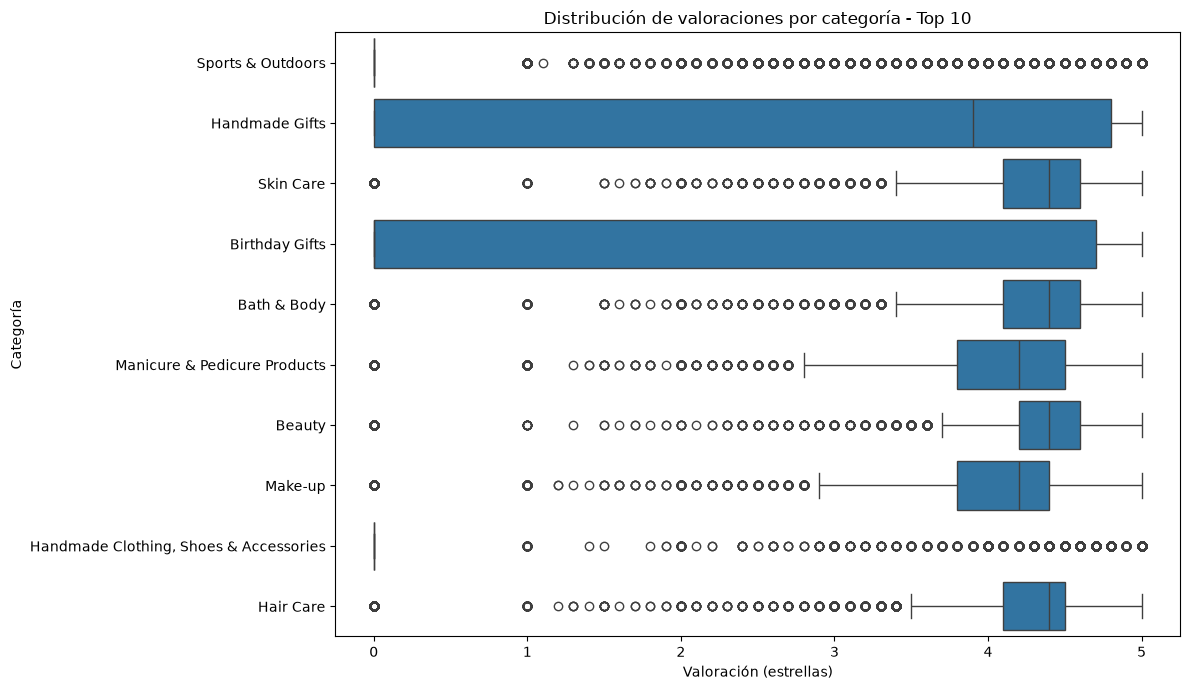

In [15]:
# Seleccionar las 10 categorías con más productos
top_10 = df_clean["category"].value_counts().head(10).index

# Crear el box plot
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df_clean[df_clean["category"].isin(top_10)],
    x="stars",
    y="category"
)

plt.title("Distribución de valoraciones por categoría - Top 10")
plt.xlabel("Valoración (estrellas)")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

### Conclusión — Box Plot de valoraciones

El gráfico muestra diferencias en la distribución de las valoraciones entre las diez categorías con mayor número de productos.

Categorías como Skin Care, Beauty y Bath & Body presentan valoraciones centrales elevadas, mientras que Make-up y Manicure & Pedicure Products muestran medianas ligeramente inferiores.

También observamos una concentración importante de valores iguales a cero en algunas categorías, como Sports & Outdoors. Estos valores podrían corresponder a productos sin reseñas, por lo que sería necesario comprobar su significado antes de extraer conclusiones definitivas.

In [16]:
# Calcular la mediana de valoraciones por categoría
medianas_stars = (
    df_clean.groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

medianas_stars.head(10)

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Laptop Accessories              4.6
Hobbies                         4.6
Luxury Food & Drink             4.6
Soft Toys                       4.5
Boxes & Organisers              4.5
Name: stars, dtype: float64

### Conclusión — Mediana de valoraciones por categoría

Tras analizar todas las categorías del dataset sin valores atípicos de precio, observamos que **Computer Memory presenta la mediana de valoración más alta, con 4,7 estrellas**.

Le siguen categorías como Beer, Wine & Spirits, Building & Construction Toys y Office Paper Products, todas con una mediana de 4,6 estrellas.

Estos resultados sugieren que los productos de Computer Memory suelen recibir valoraciones elevadas. Sin embargo, para interpretar correctamente las diferencias, sería conveniente comprobar cuántos productos tienen reseñas y si los valores de cero representan productos sin valorar.

### Part 3: Investigating the Interplay Between Product Prices and Ratings

In [17]:
# Calcular la correlación entre precio y valoración
correlacion = df_clean["price"].corr(df_clean["stars"])

print("Correlación entre precio y estrellas:", correlacion)

Correlación entre precio y estrellas: -0.07767299878181323


### Conclusión — Correlación entre precio y valoraciones

El coeficiente de correlación de Pearson entre el precio y las valoraciones de los productos es de **-0,0777**.

Este resultado indica una correlación negativa muy débil entre ambas variables. Es decir, los productos más caros tienden a recibir valoraciones ligeramente inferiores, aunque la relación es prácticamente inexistente desde el punto de vista de su intensidad.

Por tanto, el precio por sí solo no parece ser un buen indicador de la valoración que recibe un producto.

In [18]:
from scipy.stats import pearsonr

r, p_value = pearsonr(
    df_clean["price"],
    df_clean["stars"]
)

print("Correlación:", r)
print("P-value:", p_value)

Correlación: -0.0776729987818133
P-value: 0.0


### Conclusión — Significancia de la correlación

El coeficiente de correlación de Pearson entre el precio y las valoraciones es de **-0,0777**, lo que indica una relación negativa muy débil.

El p-value obtenido es inferior a 0,05, por lo que la correlación es estadísticamente significativa.

Sin embargo, su intensidad es muy baja, por lo que no podemos afirmar que exista una relación importante entre el precio de un producto y su valoración.

Desde una perspectiva empresarial, el precio por sí solo no parece ser un buen predictor de las valoraciones de los clientes.

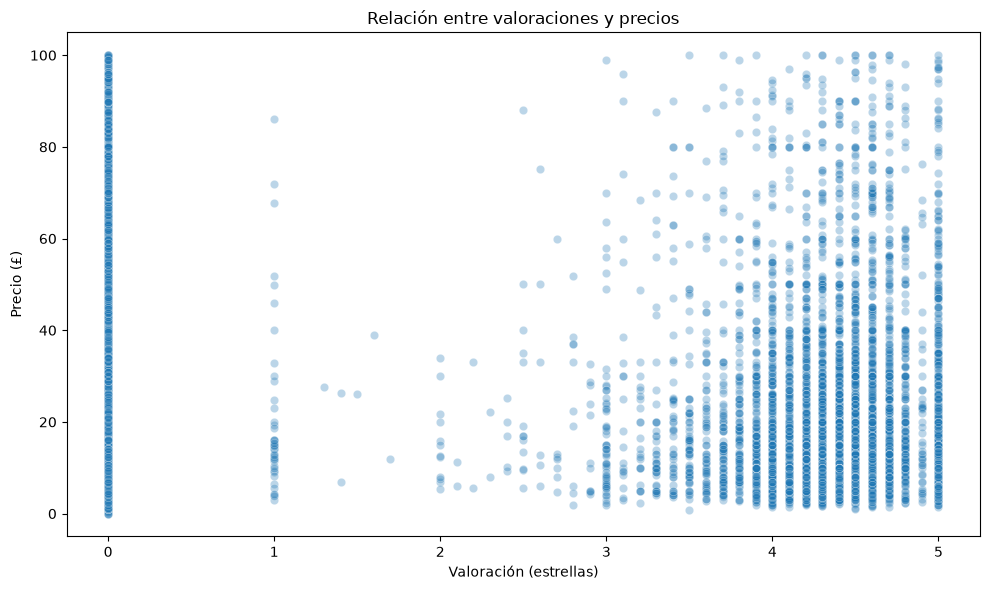

In [19]:
# Seleccionar una muestra de 10.000 productos
muestra = df_clean.sample(n=10000, random_state=42)

# Crear gráfico de dispersión
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=muestra,
    x="stars",
    y="price",
    alpha=0.3
)

plt.title("Relación entre valoraciones y precios")
plt.xlabel("Valoración (estrellas)")
plt.ylabel("Precio (£)")
plt.tight_layout()
plt.show()

### Conclusión — Scatter Plot

El gráfico de dispersión muestra que no existe una relación lineal clara entre el precio y las valoraciones de los productos.

La mayoría de las valoraciones se concentran entre 4 y 5 estrellas, independientemente del precio.

También observamos numerosos productos con 0 estrellas, que podrían corresponder a productos sin valoraciones.

Estos resultados son coherentes con el coeficiente de correlación de Pearson obtenido (-0,0777), que indica una relación negativa muy débil entre ambas variables.

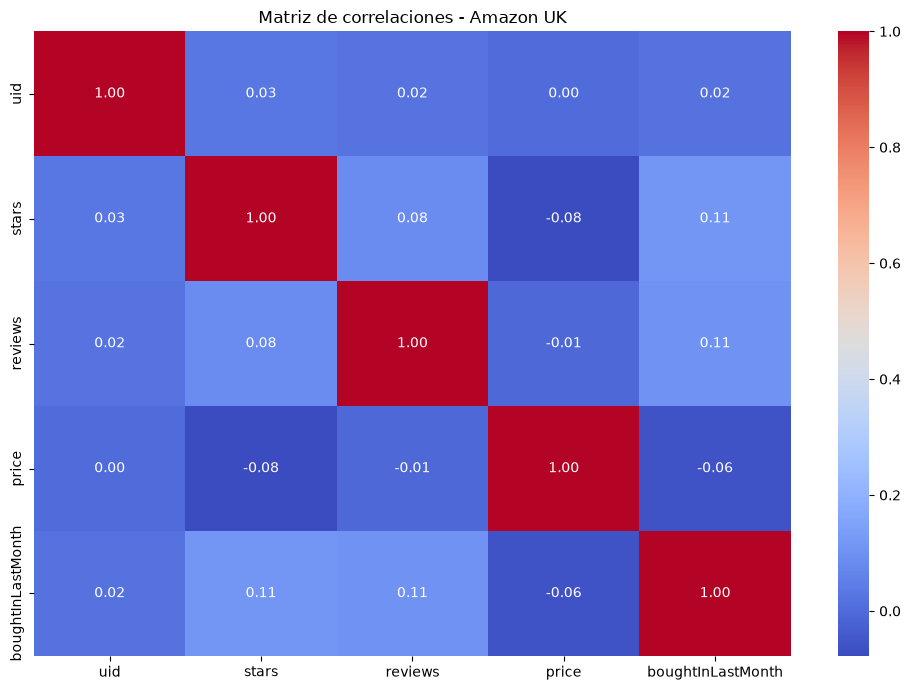

In [20]:
# Seleccionar las columnas numéricas
numericas = df_clean.select_dtypes(include="number")

# Calcular la matriz de correlaciones
matriz_corr = numericas.corr()

# Crear el heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    matriz_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlaciones - Amazon UK")
plt.tight_layout()
plt.show()

### Conclusión — Heatmap de correlaciones

El mapa de calor muestra que las correlaciones entre las variables numéricas del dataset son, en general, muy débiles.

La relación entre precio y valoraciones es ligeramente negativa (-0,08), mientras que la correlación entre precio y número de reseñas es prácticamente nula (-0,01).

Las correlaciones positivas más elevadas aparecen entre las compras del último mes y las valoraciones, así como entre las compras y el número de reseñas (aproximadamente 0,11 en ambos casos).

Desde una perspectiva empresarial, estos resultados sugieren que ninguna de estas variables, considerada de forma aislada, presenta una relación lineal fuerte con el precio de los productos.

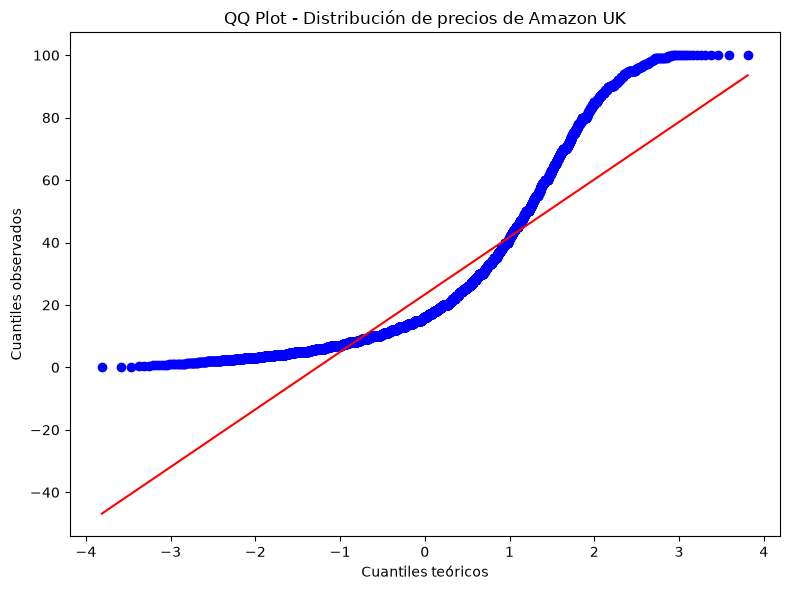

In [21]:
from scipy import stats

# Seleccionar una muestra de precios
muestra_precios = df_clean["price"].sample(n=10000, random_state=42)

# Crear el QQ Plot
plt.figure(figsize=(8, 6))

stats.probplot(muestra_precios, dist="norm", plot=plt)

plt.title("QQ Plot - Distribución de precios de Amazon UK")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")
plt.tight_layout()
plt.show()

### Conclusión — QQ Plot

El QQ Plot muestra que los precios de los productos de Amazon UK no siguen una distribución normal, ya que los puntos se alejan considerablemente de la línea de referencia.

La distribución presenta asimetría positiva, con una mayor concentración de productos de precios bajos y una proporción menor de productos con precios elevados.

Además, observamos que los valores superiores se concentran cerca de 100 £, debido a la eliminación previa de outliers mediante el método IQR.

Por tanto, concluimos que **la distribución de los precios no es normal**, incluso después de eliminar los valores atípicos.

In [22]:
# Comprobar productos con cero estrellas
df_clean[df_clean["stars"] == 0]["reviews"].value_counts().head(10)

reviews
0    1001620
Name: count, dtype: int64

### Observación sobre los productos sin valoraciones

Al analizar los productos con cero estrellas, comprobamos que **1.001.620 productos también tienen cero reseñas**, lo que representa aproximadamente el 47,3 % del dataset sin outliers.

Esto sugiere que los valores de cero estrellas corresponden a productos que todavía no han recibido valoraciones.

Por tanto, estos productos pueden distorsionar el análisis de las puntuaciones y la correlación entre precio y estrellas.

Para estudiar las valoraciones reales de los clientes, sería más adecuado excluir los productos sin reseñas y repetir el análisis de correlación.

In [23]:
# Seleccionar productos que sí tienen reseñas
df_rated = df_clean[
    (df_clean["reviews"] > 0) &
    (df_clean["stars"] > 0)
].copy()

# Calcular nuevamente la correlación
correlacion_rated = df_rated["price"].corr(df_rated["stars"])

print("Productos con valoraciones:", len(df_rated))
print("Nueva correlación:", correlacion_rated)

Productos con valoraciones: 1114343
Nueva correlación: 0.006744508067157963


### Conclusión final — Relación entre precio y valoraciones

Inicialmente, el análisis de correlación de Pearson mostró una relación negativa muy débil entre el precio y las valoraciones de los productos (r = -0,0777).

Sin embargo, detectamos que **1.001.620 productos tenían cero estrellas y cero reseñas**, lo que sugiere que no habían recibido valoraciones.

Al excluir estos productos y repetir el análisis con los **1.114.343 productos que sí tienen valoraciones**, obtuvimos una correlación de **r = 0,0067**.

Este resultado indica que prácticamente no existe una relación lineal entre el precio y las valoraciones de los productos.

**Desde una perspectiva empresarial, un precio más elevado no implica que un producto reciba mejores valoraciones.** Otros factores, como la calidad percibida, las expectativas del cliente o la experiencia de compra, podrían ser más relevantes, aunque no se han analizado en este ejercicio.